# 03 – Xây dựng và đánh giá mô hình hồi quy (Thành viên 3)
Bản chạy độc lập: chỉ cần `SeoulBikeData_clean.csv` cùng thư mục. Bản tích hợp vào notebook chung nằm ở `do_an_day_du/bao_cao/do_an_seoul_bike.ipynb` (Phần C).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
from matplotlib.ticker import FuncFormatter
BLUE, ORANGE, INK, INK2, GRID, AXIS = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': AXIS, 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'axes.titlecolor': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 11.5, 'axes.titlelocation': 'left', 'axes.labelsize': 10, 'font.size': 10, 'axes.grid': True,
    'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False})

def vn_num(x, nd=0):
    return f'{x:,.{nd}f}'.replace(',', '#').replace('.', ',').replace('#', '.')   # 1.234,5

THOUSANDS = FuncFormatter(lambda v, _: vn_num(v))

### C.1 Chọn biến và mã hóa
- Biến mục tiêu: `Rented Bike Count`. Dùng cùng phạm vi với Phần B: `df_run` (8.465 giờ hoạt động); 295 giờ hệ thống ngừng đều có 0 lượt thuê nên không đưa vào mô hình.
- Biến đầu vào: `Hour`, `IsWeekend`, các biến thời tiết, `Seasons`, `Holiday`. Không đưa `Month` (trùng thông tin với `Seasons`), `DayOfWeek`, `Date`.
- Khác với gợi ý chọn biến |r| ≥ 0,3 ở Phần B, mô hình dùng toàn bộ biến thời tiết: Ridge xử lý được đa cộng tuyến (nhiệt độ – điểm sương r = 0,91) và mưa tuy |r| thấp nhưng làm nhu cầu giảm rất mạnh.
- `Hour`, `Seasons`, `Holiday` được mã hóa one-hot (quan hệ giữa giờ và số lượt thuê có hai đỉnh, không tuyến tính).

In [3]:
SEED = 42
DROP_OFF = True   # True: loại 295 giờ hệ thống ngừng (Functioning Day = No) như Phần B; False: giữ lại
MODEL_FIG = Path('figures/model'); MODEL_FIG.mkdir(parents=True, exist_ok=True)
TARGET, TEMP = 'Rented Bike Count', 'Temperature(°C)'
df = pd.read_csv('SeoulBikeData_clean.csv', encoding='utf-8-sig')
if DROP_OFF:
    df = df[df['Functioning Day'] == 'Yes']
y = df[TARGET]
X = df.drop(columns=[TARGET, 'Date', 'Month', 'DayOfWeek', 'Functioning Day'])
X = pd.get_dummies(X, columns=['Hour', 'Seasons', 'Holiday'], drop_first=True, dtype=int)
print(X.shape, y.shape)

(8465, 36) (8465,)


### C.2 Chia train/test 80/20
Cả ba mô hình dùng chung một cách chia (`random_state` cố định) và cùng một `KFold` để so sánh được.

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED)
print('Train:', len(Xtr), '| Test:', len(Xte))

Train: 6772 | Test: 1693


### C.3 Ba mô hình
- **Hồi quy tuyến tính đơn:** chỉ dùng nhiệt độ.
- **Hồi quy tuyến tính đa biến:** toàn bộ biến thời gian, thời tiết và phân loại.
- **Ridge:** pipeline (chuẩn hóa + Ridge), chọn `alpha` bằng Grid Search với 5-fold cross-validation.

In [5]:
models = {
    'Hồi quy tuyến tính đơn': (LinearRegression(), [TEMP]),
    'Hồi quy tuyến tính đa biến': (LinearRegression(), list(X.columns)),
}
grid = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': np.logspace(-2, 3, 20)}, cv=kf, scoring='r2')
grid.fit(Xtr, ytr)
print('alpha tốt nhất:', round(grid.best_params_['ridge__alpha'], 3))
models['Ridge Regression'] = (grid.best_estimator_, list(X.columns))

alpha tốt nhất: 14.384


### C.4 Đánh giá: MAE, RMSE, R² (tập test) và 5-fold CV R² (tập train)

In [6]:
rows, preds = [], {}
for name, (m, cols) in models.items():
    cv = cross_val_score(m, Xtr[cols], ytr, cv=kf, scoring='r2')
    m.fit(Xtr[cols], ytr)
    p = m.predict(Xte[cols]); preds[name] = p
    rows.append({'Mô hình': name, 'MAE': mean_absolute_error(yte, p),
                 'RMSE': np.sqrt(mean_squared_error(yte, p)), 'R²': r2_score(yte, p),
                 'CV R² (TB)': cv.mean(), 'CV R² (độ lệch chuẩn)': cv.std()})
res = pd.DataFrame(rows).round(3)
res.to_excel('model_comparison.xlsx', index=False)
res

,Mô hình,MAE,RMSE,R²,CV R² (TB),CV R² (độ lệch chuẩn)
0,Hồi quy tuyến tính đơn,381.239,514.822,0.325,0.313,0.009
1,Hồi quy tuyến tính đa biến,275.156,363.143,0.664,0.660,0.011
2,Ridge Regression,275.129,363.001,0.664,0.660,0.011


### C.5 Biểu đồ
Ba hình dùng chung bảng màu và định dạng số của Phần B; hình được lưu vào `figures/model/` để đưa vào báo cáo.

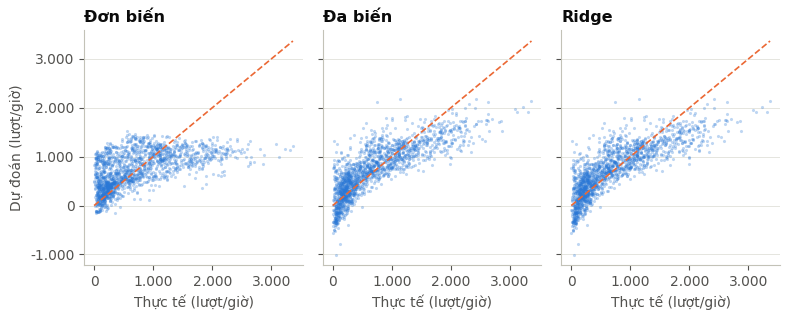

In [7]:
SHORT = ['Đơn biến', 'Đa biến', 'Ridge']
names = list(models)

def save_model_fig(fig, name):
    fig.savefig(MODEL_FIG / name, dpi=200, bbox_inches='tight', facecolor='white'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(8, 3.3), sharex=True, sharey=True)
for a, k, t in zip(ax, names, SHORT):
    a.scatter(yte, preds[k], s=5, color=BLUE, alpha=.3, linewidths=0)
    a.plot([0, yte.max()], [0, yte.max()], color=ORANGE, ls='--', lw=1.2)
    a.set_title(t); a.set_xlabel('Thực tế (lượt/giờ)'); a.xaxis.set_major_formatter(THOUSANDS); a.yaxis.set_major_formatter(THOUSANDS)
ax[0].set_ylabel('Dự đoán (lượt/giờ)')
plt.tight_layout(); save_model_fig(fig, '10_thuc_te_vs_du_doan.png')

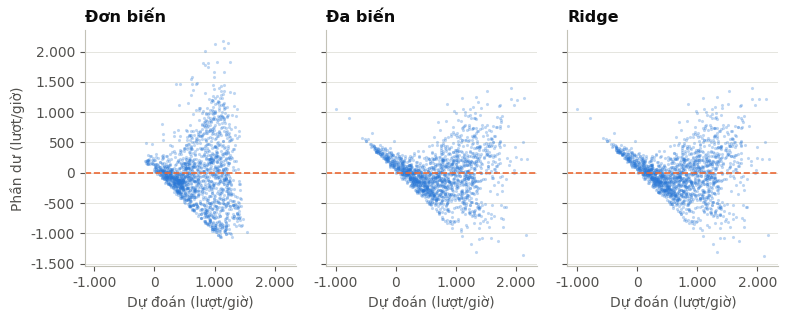

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(8, 3.3), sharex=True, sharey=True)
for a, k, t in zip(ax, names, SHORT):
    a.scatter(preds[k], yte - preds[k], s=5, color=BLUE, alpha=.3, linewidths=0)
    a.axhline(0, color=ORANGE, ls='--', lw=1.2)
    a.set_title(t); a.set_xlabel('Dự đoán (lượt/giờ)'); a.xaxis.set_major_formatter(THOUSANDS); a.yaxis.set_major_formatter(THOUSANDS)
ax[0].set_ylabel('Phần dư (lượt/giờ)')
plt.tight_layout(); save_model_fig(fig, '11_residual_plot.png')

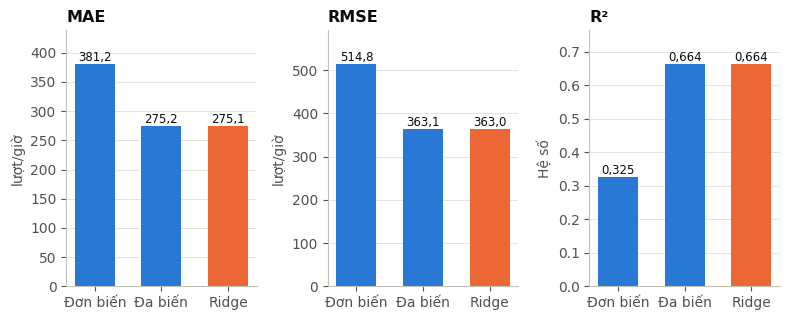

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(8, 3.3))
for a, col, nd in zip(ax, ['MAE', 'RMSE', 'R²'], [1, 1, 3]):
    a.bar(range(3), res[col], color=[BLUE, BLUE, ORANGE], width=0.6); a.set_title(col)
    a.set_xticks(range(3)); a.set_xticklabels(SHORT); a.set_ylabel('Hệ số' if col == 'R²' else 'lượt/giờ')
    a.set_ylim(0, res[col].max() * 1.15)
    for i, v in enumerate(res[col]): a.text(i, v, vn_num(v, nd), ha='center', va='bottom', fontsize=8.5)
plt.tight_layout(); save_model_fig(fig, '12_so_sanh_mo_hinh.png')

### C.6 Mô hình tốt nhất và các hệ số lớn nhất của Ridge

In [10]:
print('Mô hình tốt nhất (RMSE thấp nhất):', res.loc[res['RMSE'].idxmin(), 'Mô hình'])
print(pd.Series(grid.best_estimator_[-1].coef_, X.columns).sort_values(key=abs, ascending=False).head(8).round(1))

Mô hình tốt nhất (RMSE thấp nhất): Ridge Regression
Humidity(%)                 -209.2
Dew point temperature(°C)    171.5
Hour_18                      159.2
Seasons_Winter              -154.0
Temperature(°C)              141.2
Hour_19                      104.4
Hour_8                       103.9
Hour_20                       87.6
dtype: float64
